# 03 — TF-IDF Baseline Matching

## Project overview
TF-IDF converts candidate and job text into numerical vectors. Row-wise cosine similarity provides the first transparent text-matching baseline.

**Outputs:** `tfidf_baseline_results.csv` and `tfidf_vectorizer.pkl`.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [15]:
df=pd.read_csv(r"D:\Instant AI\AI\Graduation Project\My Project\Data\processed_data.csv")

## 1. Load the processed text
Use the common `processed_data.csv` created in Notebook 02.

In [16]:
df[["candidate_text","job_text","matched_score"]]

,candidate_text,job_text,matched_score
0,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,0.850000
1,fresher looking to join as a data analyst and ...,machine learning (ml) engineer m.sc in compute...,0.750000
2,"['software development', 'machine learning', '...","executive/ senior executive- trade marketing, ...",0.416667
3,to obtain a position in a fast-paced business ...,business development executive bachelor/honors...,0.760000
4,professional accountant with an outstanding wo...,senior ios engineer bachelor of science (bsc) ...,0.650000
...,...,...,...
9539,"['mathematical modelling', 'machine learning',...",data engineer bachelor of science (bsc) 5 to 8...,0.683333
9540,expertise eda modeler. i like to learn what my...,executive/ sr. executive -it bachelor of scien...,0.650000
9541,looking for roles related to application devel...,executive - vat bba in accounting and finance ...,0.650000
9542,"['machine learning', 'natural language process...",asst. manager/ manger (administrative) bachelo...,0.650000


## 2. Create a leakage-safe TF-IDF representation
The dataset is split into training and test rows before fitting TF-IDF. The vectorizer learns its vocabulary and IDF values from training text only, then transforms the full dataset for downstream matching.

### Train/test split
An 80/20 row-level split is created with `random_state=42`. TF-IDF is fitted only on the training candidate and job text. The test rows remain unseen during fitting.

In [17]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    max_features=20000
)

In [18]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42
)

df["split"] = "train"
df.loc[test_idx, "split"] = "test"

train_text = pd.concat([
    df.loc[train_idx, "candidate_text"],
    df.loc[train_idx, "job_text"]
], ignore_index=True)

all_text = pd.concat([
    df["candidate_text"],
    df["job_text"]
], ignore_index=True)

In [19]:
tfidf_vectorizer.fit(train_text)

tfidf_matrix = tfidf_vectorizer.transform(all_text)

In [20]:
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (19088, 20000)


## 3. Separate candidate and job vectors
The combined matrix is split back into candidate and job vectors using the original row count.

In [21]:
candidate_vectors=tfidf_matrix[:len(df)]
job_vectors=tfidf_matrix[len(df):]

In [22]:
print("Candidate vectors shape:", candidate_vectors.shape)
print("Job vectors shape:", job_vectors.shape)

Candidate vectors shape: (9544, 20000)
Job vectors shape: (9544, 20000)


## 4. Calculate similarity
Because TF-IDF vectors are normalized, the row-wise dot product represents cosine similarity.

In [23]:
pairwise_similarity=(
    candidate_vectors.multiply(job_vectors).sum(axis=1)
)

In [24]:
pairwise_similarity = np.asarray(
    pairwise_similarity
).ravel()

In [25]:
df['tfidf_similarity'] = pairwise_similarity


In [26]:
test_df = df.loc[test_idx].copy()

spearman_result = spearmanr(
    test_df["matched_score"],
    test_df["tfidf_similarity"]
)

print("Test Spearman:", spearman_result.correlation)


Test Spearman: 0.3816986947215274


## 5. Evaluate the baseline
Evaluate TF-IDF similarity on the held-out test set using descriptive statistics, correlation, MAE, and a scatter plot. The test set is not used to fit the vectorizer.

In [27]:
df[
    [
        'candidate_text',
        'job_text',
        'matched_score',
        'tfidf_similarity'
    ]
].head(10)

,candidate_text,job_text,matched_score,tfidf_similarity
0,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,0.850000,0.003533
1,fresher looking to join as a data analyst and ...,machine learning (ml) engineer m.sc in compute...,0.750000,0.056484
2,"['software development', 'machine learning', '...","executive/ senior executive- trade marketing, ...",0.416667,0.000000
3,to obtain a position in a fast-paced business ...,business development executive bachelor/honors...,0.760000,0.012055
4,professional accountant with an outstanding wo...,senior ios engineer bachelor of science (bsc) ...,0.650000,0.004766
5,"to secure an it specialist, desktop support, n...",ai engineer bachelors or masters degree in com...,0.850000,0.014965
6,"['machine learning', 'linear regression', 'rid...",senior ios engineer bachelor of science (bsc) ...,0.650000,0.002348
7,"['maintenance', 'corrective maintenance', 'doc...",senior ios engineer bachelor of science (bsc) ...,0.650000,0.006297
8,certified data analyst with a degree in electr...,mechanical engineer bachelor of science (bsc) ...,0.550000,0.002118
9,"['django', 'python', 'relational databases', '...",business development executive bachelor/honors...,0.383333,0.001965


In [28]:
df[
    ['matched_score', 'tfidf_similarity']
].describe()

,matched_score,tfidf_similarity
count,9544.000000,9544.000000
mean,0.660831,0.014331
std,0.167040,0.015251
min,0.000000,0.000000
25%,0.583333,0.003874
50%,0.683333,0.009794
75%,0.793333,0.019669
max,0.970000,0.196617


In [29]:
correlation = df[
    ['matched_score', 'tfidf_similarity']
].corr().iloc[0, 1]

print("Correlation:", correlation)

Correlation: 0.3115470389080018


In [30]:
df['absolute_error'] = (
    df['matched_score'] -
    df['tfidf_similarity']
).abs()

In [31]:
mae = df['absolute_error'].mean()

print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.6465006936993132


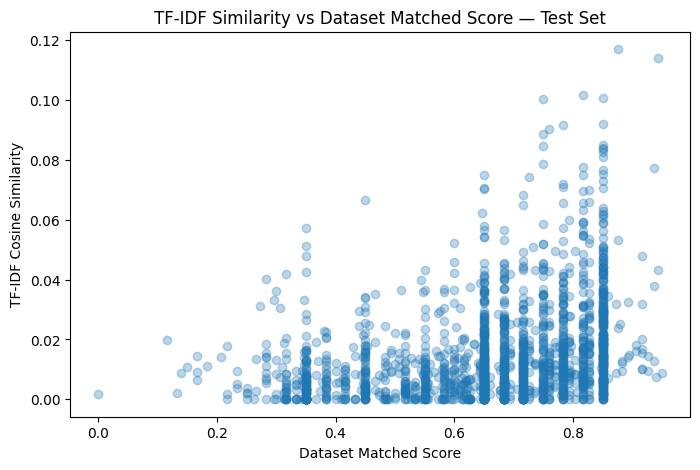

In [32]:
plt.figure(figsize=(8, 5))

plt.scatter(
    test_df["matched_score"],
    test_df["tfidf_similarity"],
    alpha=0.3
)

plt.xlabel("Dataset Matched Score")
plt.ylabel("TF-IDF Cosine Similarity")
plt.title("TF-IDF Similarity vs Dataset Matched Score — Test Set")

plt.show()

## 6. Save the baseline results
Save similarity results for later comparison.

In [33]:
df.to_csv(
    r"D:\Instant AI\AI\Graduation Project\My Project\Data\tfidf_baseline_results.csv",
    index=False
)

## 7. Save the TF-IDF vectorizer
Save the fitted vectorizer so the learned vocabulary can be reused.

In [34]:
import joblib

joblib.dump(
    tfidf_vectorizer,
    r'D:\Instant AI\AI\Graduation Project\My Project\Models\tfidf_vectorizer.pkl'
)

['D:\\Instant AI\\AI\\Graduation Project\\My Project\\Models\\tfidf_vectorizer.pkl']

## Conclusion
TF-IDF provides the project with a clear lexical-similarity baseline. The vectorizer is fitted using training text only, while the held-out test rows are used for baseline evaluation. Later stages add supervised classification, Word2Vec semantics, and explicit skill matching.

In [35]:
print("TF-IDF baseline completed successfully.")

print("Dataset shape:", df.shape)
print("Train rows:", (df["split"] == "train").sum())
print("Test rows:", (df["split"] == "test").sum())
print("Average TF-IDF similarity:", df["tfidf_similarity"].mean())
print("Test Pearson correlation:", test_df["matched_score"].corr(test_df["tfidf_similarity"]))
print("Test MAE:", np.mean(np.abs(test_df["matched_score"] - test_df["tfidf_similarity"])))


TF-IDF baseline completed successfully.
Dataset shape: (9544, 36)
Train rows: 7635
Test rows: 1909
Average TF-IDF similarity: 0.014330514504449367
Test Pearson correlation: 0.32473921886079316
Test MAE: 0.6436857139051386
